# OpenMapTiles layers and classes in the crops

Effort to categorize and hand-label layers, classes, and subclasses as semantic labels

In [1]:
import collections, gzip, json, sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

sys.path.insert(0, "..")
from data_preprocess.create_coco_osm import PARTS, SKIP, label_for, make_to_px
%matplotlib inline

CROPS = Path("../crops_flushing")
N_COLOR_CROPS = 300   # crops sampled for colours (all crops are used for counts)
TOP_N = 40            # (layer, class, geometry) combinations shown in the charts
TOP_COLORS = 3
GEOM_COLORS = {"polygon": "#2a78d6", "line": "#eb6834", "point": "#1baf7a"}   # validated categorical slots 1-3

files = sorted(CROPS.glob("*.geojson.gz"))
print(len(files), "crops")

{'path': [('transportation', 'path', 'cycleway', 'line'), ('transportation', 'path', 'bridleway', 'line'), ('transportation', 'path', 'path', 'line'), ('transportation', 'path', 'platform', 'line'), ('transportation', 'path', 'corridor', 'line'), ('transportation', 'track', None, 'line'), ('transportation', 'path', 'footway', 'line'), ('transportation', 'path', 'steps', 'line'), ('transportation', 'path', 'pedestrian', 'line')], 'park': [('park', 'wildlife_refuge', None, 'polygon'), ('park', 'National Recreation Area', None, 'polygon'), ('park', 'protected_area', None, 'polygon'), ('park', 'nature_reserve', None, 'polygon'), ('landcover', 'grass', 'park', 'polygon')], 'plaza': [('transportation', 'path', 'platform', 'polygon'), ('transportation', 'path', 'pedestrian', 'polygon'), ('transportation', 'path', 'footway', 'polygon')], 'railway': [('transportation', 'rail', 'rail', 'line')], 'administrative': [('boundary', None, None, 'line')], 'cemetery': [('landuse', 'cemetery', None, 'pol

## Table of features in each geojson and how they are labeled

In [2]:
def mapped_label(layer, cls, subclass, geom):
    if (layer, cls) in SKIP or (layer, "*") in SKIP:
        return "(skipped)"
    if geom == "point":
        return "(point: not used)"
    return label_for(layer, cls, subclass, geom)

rows = []
for f in files:
    for feat in json.load(gzip.open(f, "rt"))["features"]:
        g, props = feat["geometry"], feat["properties"]
        # lambda function to tell if polygon, line etc.
        geom = "polygon" if "Polygon" in g["type"] else "line" if "LineString" in g["type"] else "point"
        rows.append({"crop": f.name, "layer": props["omt_layer"], "class": props.get("class"),
                     "subclass": props.get("subclass"), "geom": geom})
features = pd.DataFrame(rows)
features["label"] = [mapped_label(l, c, s, g) for l, c, s, g in zip(features.layer, features["class"], features["subclass"], features.geom)]

table = (features.groupby(["layer", "class", "subclass", "geom", "label"], dropna=False)
         .agg(features=("crop", "size"), crops=("crop", "nunique"))
         .reset_index().sort_values("features", ascending=False))
table["share_of_crops"] = (table.crops / len(files)).round(3)
table

,layer,class,subclass,geom,label,features,crops,share_of_crops
8,building,NaN,NaN,polygon,building,38086,4461,0.892
91,transportation_name,minor,NaN,line,(skipped),14437,4216,0.843
62,transportation,minor,NaN,line,street,12774,4220,0.844
69,transportation,path,footway,line,path,7918,4400,0.880
83,transportation,service,NaN,line,street,7112,2932,0.586
...,...,...,...,...,...,...,...,...
103,transportation_name,secondary,junction,point,(skipped),1,1,0.000
92,transportation_name,minor_construction,NaN,line,(skipped),1,1,0.000
70,transportation,path,footway,polygon,plaza,1,1,0.000
46,landuse,toilets,NaN,polygon,unknown,1,1,0.000


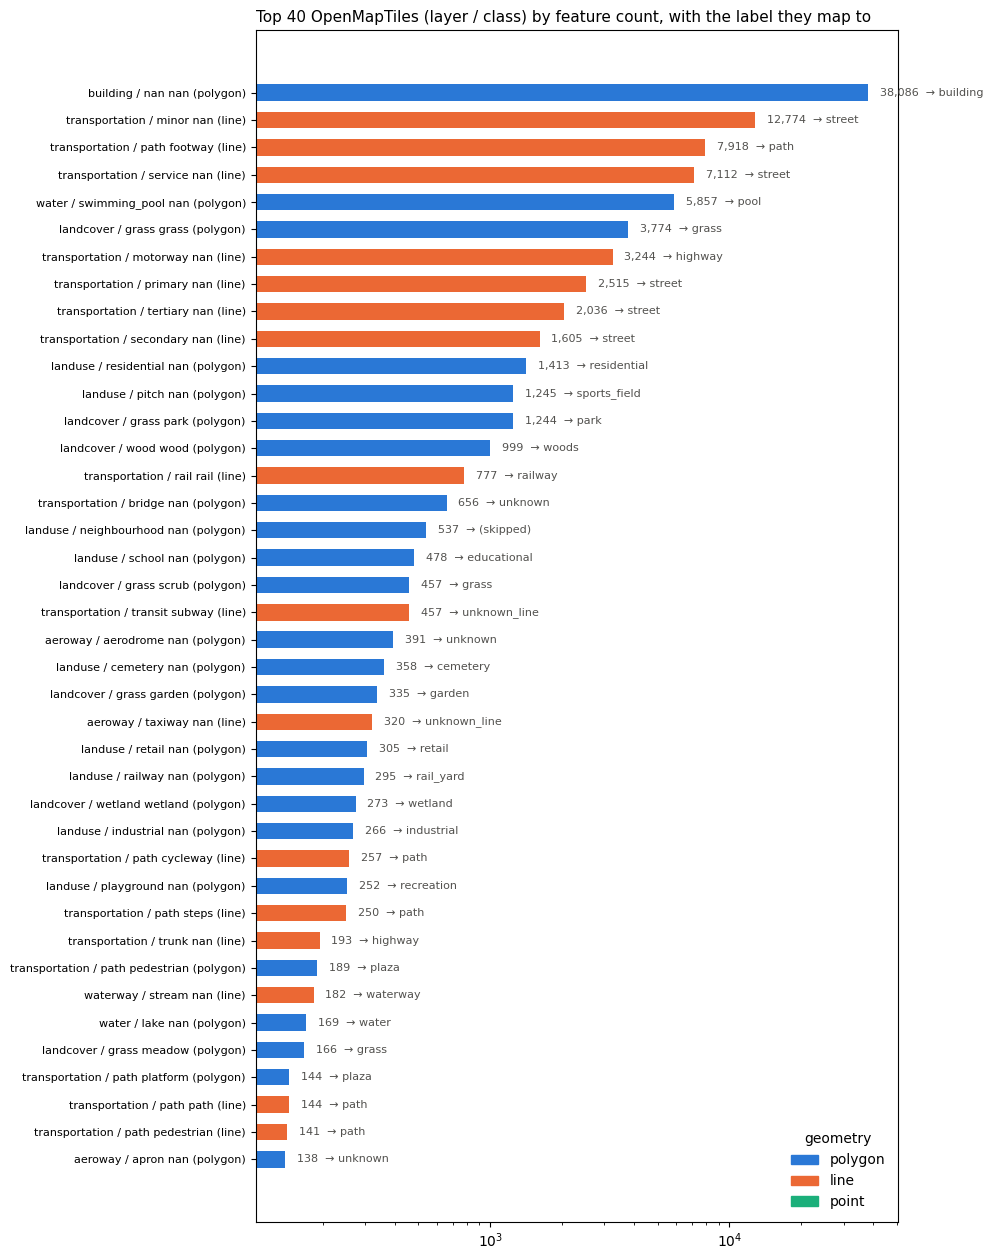

In [12]:
table_droplayer = table[table['layer']!='transportation_name']
top = table_droplayer.head(TOP_N).iloc[::-1]
names = [f"{l} / {c} {s} ({g})" for l, c, s, g in zip(top.layer, top["class"], top["subclass"], top.geom)]
fig, ax = plt.subplots(figsize=(10, 0.28 * len(top) + 1.5))
ax.barh(names, top.features, color=top.geom.map(GEOM_COLORS), height=0.6)
ax.set_xscale("log")
for y, (v, lab) in enumerate(zip(top.features, top.label)):
    ax.text(v * 1.12, y, f"{v:,}  → {lab}", va="center", fontsize=8, color="#52514e")
ax.tick_params(axis="y", labelsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=v) for v in GEOM_COLORS.values()]
ax.legend(handles, GEOM_COLORS.keys(), loc="lower right", frameon=False, title="geometry")
ax.set_title(f"Top {len(top)} OpenMapTiles (layer / class) by feature count, with the label they map to",
             loc="left", fontsize=11)
fig.tight_layout()

## How the render carto script renders each shape

In [13]:
import utils.render_carto as rc

rows = [("landcover/landuse", k, c, 1) for k, c in rc.AREA_COLORS.items() if c]
rows += [("water", "water", rc.WATER, 2), ("waterway", "waterway", rc.WATER, 3),
         ("building", "building", "#d9d0c9", 4), ("rail", "rail", "#707070", 17)]
rows += [("road", k, v[0], 8 + rc.ROAD_ORDER.index(k)) for k, v in rc.ROADS.items()]
rows += [("path", k, v[0], 7) for k, v in rc.PATH_STYLE.items()]
rows += [("boundary", "boundary", rc.BOUNDARY_COLOR, 6), ("park", "park", rc.PROTECTED_COLOR, 5),
         ("transportation", "track", "#996600", 7), ("transportation", "pedestrian", "#dddde8", 7)]
colors = pd.DataFrame(rows, columns=["layer", "class", "color", "zorder"]).sort_values("zorder")

shared = colors[colors.duplicated("color", keep=False)].groupby("color")["class"].apply(list)
shared

color
#008000                                    [park, bridleway]
#aad3df                                    [water, waterway]
#aae0cb                                       [pitch, track]
#add19e                                       [forest, wood]
#aedfa3                                  [orchard, vineyard]
#c7c7b4                           [construction, brownfield]
#cdebb0            [grass, grassland, meadow, village_green]
#ddecec                                       [ice, glacier]
#dffce2             [stadium, playground, recreation_ground]
#ebdbe8                                [railway, industrial]
#fa8072                         [steps, pedestrian, footway]
#ffffe5    [school, kindergarten, university, college, li...
#ffffff                           [service, minor, tertiary]
Name: class, dtype: object

In [14]:
colors["layer"] = colors.layer.replace({"road": "transportation", "path": "transportation", "rail": "transportation",
                                        "landcover/landuse": "landcover,landuse"}).str.split(",")
colors = colors.explode("layer")
colors["class"] = colors["class"].mask(colors.color == "#dddde8", "pedestrian_area")

sub = ((table.layer == "landcover") & table.subclass.isin(rc.AREA_COLORS)) | ((table["class"] == "path") & table.subclass.isin(rc.PATH_STYLE))
key = table.subclass.where(sub, table["class"])
key = key.mask(table.layer.isin(["water", "waterway", "building", "boundary", "park"]), table.layer)
key = key.mask((table.subclass == "pedestrian") & (table.geom == "polygon"), "pedestrian_area")
m = table.assign(key=key).merge(colors.rename(columns={"class": "key"}), on=["layer", "key"]) #  how="left"
m.to_csv("label_colors.csv")

In [6]:
m.shape

(73, 11)